# Preprocessing

In this notebook we prepare the cleaned data for modelling: text normalisation, label encoding, scaling, TF-IDF and padded sequences. Everything that is learned (vocabulary, TF-IDF, scaler) is fitted on the train set only, so there is no data leakage.

In [1]:
import re, json, unicodedata, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.titleweight": "bold"})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, IMG, REP = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "images", ROOT / "reports"
for p in (PROC, IMG, REP):
    p.mkdir(parents=True, exist_ok=True)

EMOTIONS = ["anger", "fear", "joy", "love", "sadness", "surprise"]
SPLITS = ["train", "val", "test"]
RANDOM_STATE = 42

NOTES = {}

def save_fig(fig, name):
    fig.savefig(IMG / f"{name}.png", dpi=200, bbox_inches="tight")

def note(name, text):
    NOTES[name] = text
    print("TAKEAWAY ->", text)

In [2]:
import joblib, scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.utils.class_weight import compute_class_weight

data = {s: pd.read_csv(PROC / f"{s}_clean.csv") for s in SPLITS}
train, val, test = data["train"], data["val"], data["test"]
print({s: d.shape for s, d in data.items()})

{'train': (15923, 3), 'val': (1993, 3), 'test': (2000, 3)}


## 1. Text normalisation

For the ML models: lower case, keep only letters and remove stop words. Negation words (not, no, never...) are kept because they change the meaning. The original text is kept for the deep learning models.

In [3]:
NEGATIONS = {"no", "not", "nor", "never", "cannot", "none", "nothing", "nobody", "neither", "nowhere", "without"}
STOP = set(ENGLISH_STOP_WORDS) - NEGATIONS
print(f"{len(STOP)} stop-words used; negations kept: {sorted(NEGATIONS & set(ENGLISH_STOP_WORDS))}")

def normalize_for_ml(text):
    toks = re.sub(r"[^a-z\s]", " ", text.lower()).split()
    kept = [t for t in toks if t not in STOP]
    return " ".join(kept if kept else toks)

for d in data.values():
    d["text_ml"] = d.text.map(normalize_for_ml)
train[["text", "text_ml"]].head(6)

307 stop-words used; negations kept: ['cannot', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'nowhere', 'without']


,text,text_ml
0,i didnt feel humiliated,didnt feel humiliated
1,i can go from feeling so hopeless to so damned...,feeling hopeless damned hopeful just cares awake
2,im grabbing a minute to post i feel greedy wrong,im grabbing minute post feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...,feeling nostalgic fireplace know property
4,i am feeling grouchy,feeling grouchy
5,ive been feeling a little burdened lately wasn...,ive feeling little burdened lately wasnt sure


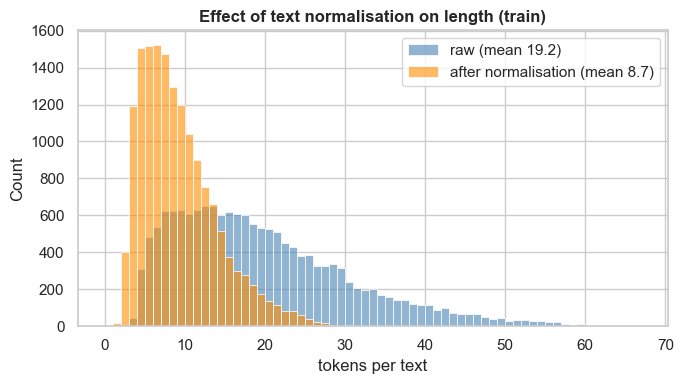

TAKEAWAY -> Normalisation shrinks the average text from 19.2 to 8.7 tokens (54% fewer), keeping the content words and negations.


In [4]:
tok_before = train.text.str.split().str.len(); tok_after = train.text_ml.str.split().str.len()
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(tok_before, bins=range(0, int(tok_before.max()) + 2), ax=ax, color="steelblue", label=f"raw (mean {tok_before.mean():.1f})", alpha=0.6)
sns.histplot(tok_after, bins=range(0, int(tok_before.max()) + 2), ax=ax, color="darkorange", label=f"after normalisation (mean {tok_after.mean():.1f})", alpha=0.6)
ax.set_xlabel("tokens per text"); ax.set_title("Effect of text normalisation on length (train)"); ax.legend()
plt.tight_layout(); save_fig(fig, "15_normalisation_effect"); plt.show()
note("15_normalisation_effect", f"Normalisation shrinks the average text from {tok_before.mean():.1f} to {tok_after.mean():.1f} tokens "
     f"({(1 - tok_after.mean() / tok_before.mean()) * 100:.0f}% fewer), keeping the content words and negations.")

The plot shows the text length before and after removing the stop words.

## 2. Label encoding and class weights

Labels are encoded alphabetically (anger = 0 ... surprise = 5). Class weights are calculated from the train set so that rare classes count more in training.

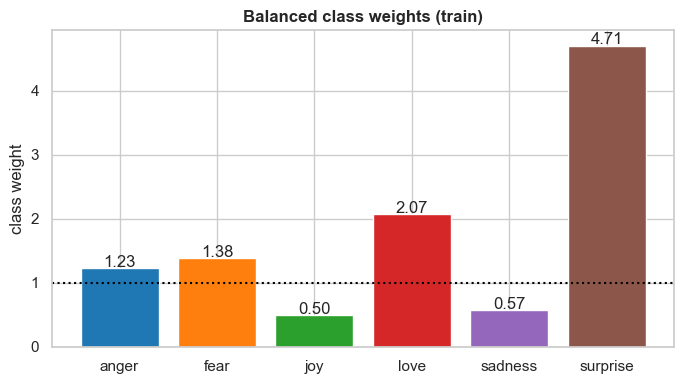

TAKEAWAY -> Weights range from 0.50 ('joy') to 4.71 ('surprise'): an error on the rarest class counts 9.5× more than on the most common one.


,id,train_samples,balanced_weight
label,,,
anger,0,2152,1.233
fear,1,1923,1.380
joy,2,5340,0.497
love,3,1283,2.068
sadness,4,4661,0.569
surprise,5,564,4.705


In [5]:
label2id = {lab: i for i, lab in enumerate(sorted(EMOTIONS))}
id2label = {i: l for l, i in label2id.items()}
for d in data.values():
    d["label_id"] = d.label.map(label2id)
    assert d.label_id.notna().all()

cw = compute_class_weight("balanced", classes=np.arange(len(label2id)), y=train.label_id.values)
class_weights = {int(i): float(w) for i, w in enumerate(cw)}
cw_table = pd.DataFrame({"label": list(label2id), "id": list(label2id.values()), "train_samples": train.label.value_counts().reindex(list(label2id)).values,
                         "balanced_weight": cw.round(3)}).set_index("label")
json.dump({"label2id": label2id, "id2label": id2label, "class_weights": class_weights}, open(PROC / "label_mapping.json", "w"), indent=2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cw_table.index, cw_table.balanced_weight, color=sns.color_palette("tab10", 6)); ax.axhline(1, color="black", ls=":")
ax.set_ylabel("class weight"); ax.set_title("Balanced class weights (train)")
for i, v in enumerate(cw_table.balanced_weight): ax.text(i, v + 0.02, f"{v:.2f}", ha="center")
plt.tight_layout(); save_fig(fig, "16_class_weights"); plt.show()
note("16_class_weights", f"Weights range from {cw.min():.2f} ('{cw_table.balanced_weight.idxmin()}') to {cw.max():.2f} ('{cw_table.balanced_weight.idxmax()}'): "
     f"an error on the rarest class counts {cw.max() / cw.min():.1f}× more than on the most common one.")
cw_table

Rare classes get bigger weights. They can be used in Phase 2.

## 3. Scaling the numeric features

We check the skewness of the 5 numeric features, apply log1p on the very skewed ones (skew > 1) and then standardise all of them with StandardScaler (fitted on train only).

In [6]:
def add_features(d):
    w = d.text.str.split()
    d["word_count"] = w.str.len()
    d["char_count"] = d.text.str.len()
    d["avg_word_len"] = (d.char_count - (d.word_count - 1)) / d.word_count
    d["unique_ratio"] = w.map(lambda x: len(set(x)) / len(x))
    d["stopword_ratio"] = w.map(lambda x: float(np.mean([t in ENGLISH_STOP_WORDS for t in x])))
for d in data.values():
    add_features(d)

NUM = ["char_count", "word_count", "avg_word_len", "unique_ratio", "stopword_ratio"]
skew = train[NUM].skew().round(2)
SKEWED = [c for c in NUM if skew[c] > 1]
print("Skewness (train):\n", skew.to_string(), "\n\nlog1p applied to:", SKEWED)

Skewness (train):
 char_count        0.96
word_count        0.96
avg_word_len      0.77
unique_ratio     -0.89
stopword_ratio   -0.87 

log1p applied to: []


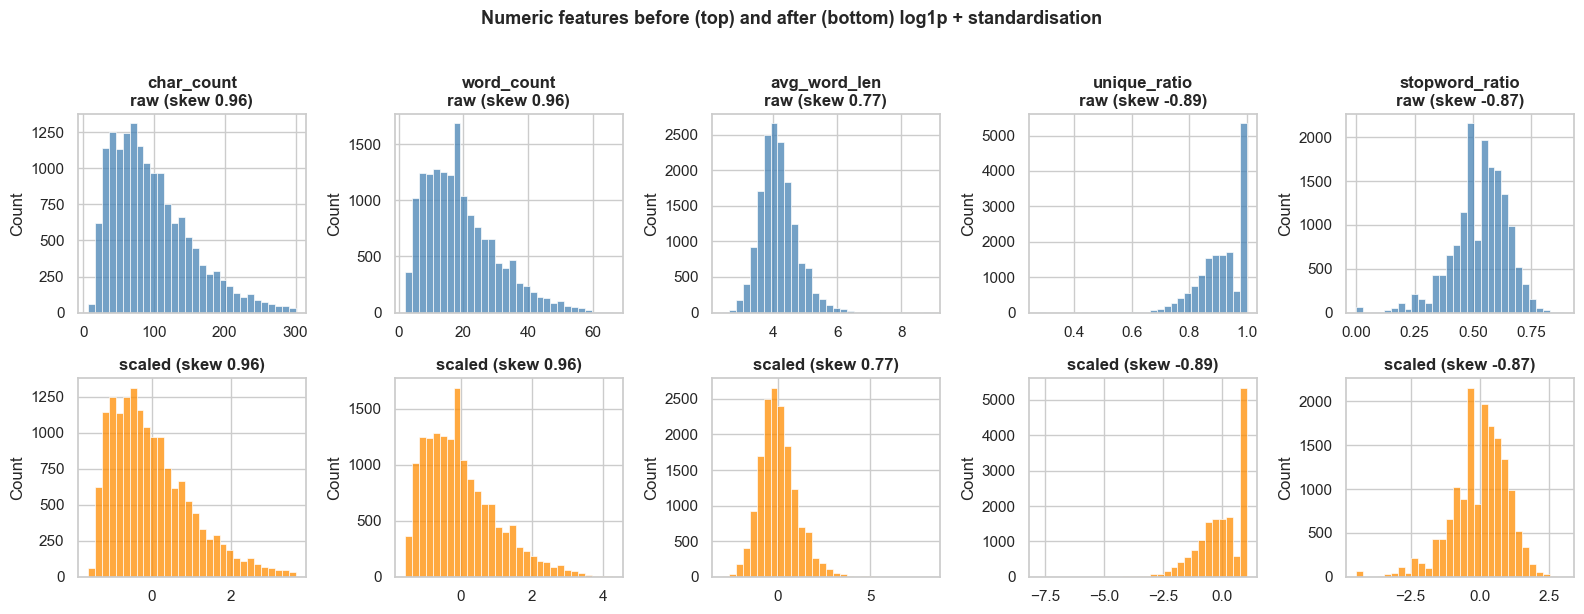

TAKEAWAY -> Scaling brings every feature to mean≈0 / std≈1; log1p reduced the skewness of no feature (none exceeded |skew|>1).


In [7]:
def transform_raw(d):
    x = d[NUM].copy()
    for c in SKEWED: x[c] = np.log1p(x[c])
    return x

scaler = StandardScaler().fit(transform_raw(train))
scaled = {s: pd.DataFrame(scaler.transform(transform_raw(d)), columns=[f"{c}_scaled" for c in NUM], index=d.index) for s, d in data.items()}
for s, d in data.items():
    data[s] = pd.concat([d, scaled[s]], axis=1)
train, val, test = data["train"], data["val"], data["test"]

fig, axes = plt.subplots(2, len(NUM), figsize=(3.2 * len(NUM), 6))
for j, c in enumerate(NUM):
    sns.histplot(train[c], ax=axes[0, j], bins=30, color="steelblue"); axes[0, j].set_title(f"{c}\nraw (skew {train[c].skew():.2f})")
    sns.histplot(train[f"{c}_scaled"], ax=axes[1, j], bins=30, color="darkorange"); axes[1, j].set_title(f"scaled (skew {train[f'{c}_scaled'].skew():.2f})")
    axes[0, j].set_xlabel(""); axes[1, j].set_xlabel("")
plt.suptitle("Numeric features before (top) and after (bottom) log1p + standardisation", y=1.02, fontsize=13, fontweight="bold")
plt.tight_layout(); save_fig(fig, "17_scaling_before_after"); plt.show()
note("17_scaling_before_after", f"Scaling brings every feature to mean≈0 / std≈1; log1p reduced the skewness of {', '.join(SKEWED) if SKEWED else 'no feature (none exceeded |skew|>1)'}.")

In [8]:
stats_tbl = pd.DataFrame({"mean (train)": train[[f"{c}_scaled" for c in NUM]].mean().round(4),
                          "std (train)": train[[f"{c}_scaled" for c in NUM]].std().round(4),
                          "mean (val)": val[[f"{c}_scaled" for c in NUM]].mean().round(3),
                          "mean (test)": test[[f"{c}_scaled" for c in NUM]].mean().round(3)})
assert np.allclose(train[[f"{c}_scaled" for c in NUM]].mean(), 0, atol=1e-6)
assert np.allclose(train[[f"{c}_scaled" for c in NUM]].std(ddof=0), 1, atol=1e-6)
joblib.dump({"scaler": scaler, "numeric_features": NUM, "log1p_features": SKEWED}, PROC / "numeric_scaler.joblib")
stats_tbl

,mean (train),std (train),mean (val),mean (test)
char_count_scaled,-0.0,1.0,-0.029,-0.006
word_count_scaled,0.0,1.0,-0.029,-0.002
avg_word_len_scaled,-0.0,1.0,0.011,-0.025
unique_ratio_scaled,0.0,1.0,0.043,0.055
stopword_ratio_scaled,0.0,1.0,-0.044,0.010


The train set has mean 0 and std 1 after scaling. Val and test are close to 0, which is expected.

## 4. TF-IDF

TF-IDF with 5000 features, unigrams and bigrams, fitted on train only.

{'train': (15923, 5000), 'val': (1993, 5000), 'test': (2000, 5000)} | non-zero entries in train: 0.18%


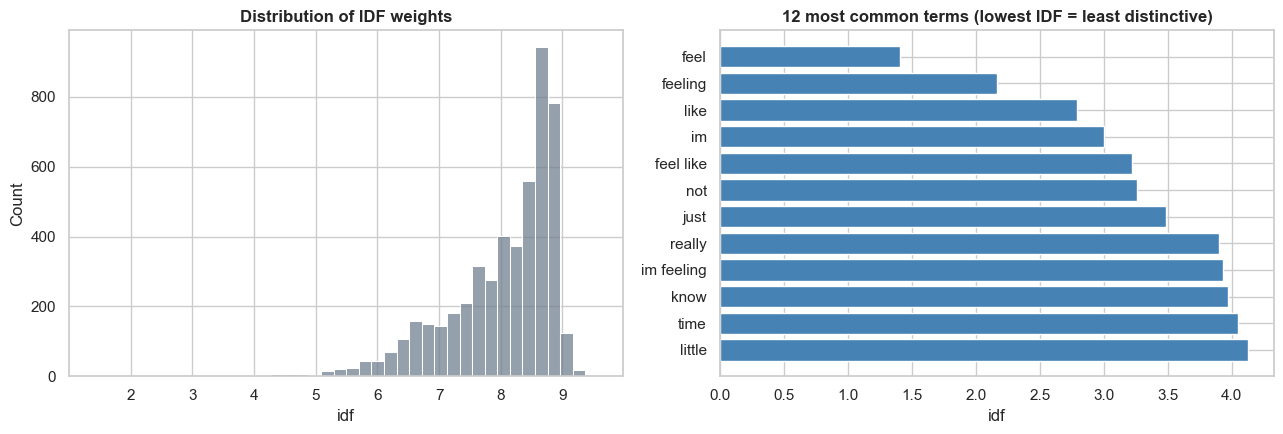

TAKEAWAY -> The TF-IDF matrix is 5,000 features wide and 99.8% sparse; the most common (least informative) term is 'feel'.


In [9]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_tfidf = {"train": tfidf.fit_transform(train.text_ml)}
X_tfidf["val"], X_tfidf["test"] = tfidf.transform(val.text_ml), tfidf.transform(test.text_ml)

density = X_tfidf["train"].nnz / np.prod(X_tfidf["train"].shape) * 100
print({s: m.shape for s, m in X_tfidf.items()}, f"| non-zero entries in train: {density:.2f}%")

feat = np.array(tfidf.get_feature_names_out()); idf = tfidf.idf_
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(idf, bins=40, ax=axes[0], color="slategray"); axes[0].set_title("Distribution of IDF weights"); axes[0].set_xlabel("idf")
lo = np.argsort(idf)[:12]; axes[1].barh(feat[lo][::-1], idf[lo][::-1], color="steelblue")
axes[1].set_title("12 most common terms (lowest IDF = least distinctive)"); axes[1].set_xlabel("idf")
plt.tight_layout(); save_fig(fig, "18_tfidf_idf"); plt.show()
note("18_tfidf_idf", f"The TF-IDF matrix is {X_tfidf['train'].shape[1]:,} features wide and {100 - density:.1f}% sparse; "
     f"the most common (least informative) term is '{feat[lo[0]]}'.")

The matrix is very sparse. Words with a low IDF appear in many texts and are less useful.

## 5. Sequences for deep learning

Words are converted to numbers using a vocabulary from the train set (10,000 words, 0 = padding, 1 = unknown word). Texts are padded or cut to MAX_LEN, which is the 99th percentile of the text length.

In [10]:
MAX_WORDS = 10_000
MAX_LEN = int(np.ceil(train.text.str.split().str.len().quantile(0.99)))
PAD, OOV = 0, 1

freq = Counter(w for t in train.text for w in t.split())
vocab = {w: i + 2 for i, (w, _) in enumerate(freq.most_common(MAX_WORDS - 2))}

def to_seq(text):
    ids = [vocab.get(w, OOV) for w in text.split()]
    ids = ids[-MAX_LEN:]
    return [PAD] * (MAX_LEN - len(ids)) + ids

X_seq = {s: np.array([to_seq(t) for t in d.text], dtype=np.int32) for s, d in data.items()}
y = {s: d.label_id.values.astype(np.int64) for s, d in data.items()}

oov_rate = {s: float(((X_seq[s] == OOV).sum() / (X_seq[s] != PAD).sum()) * 100) for s in SPLITS}
trunc_rate = {s: float((d.text.str.split().str.len() > MAX_LEN).mean() * 100) for s, d in data.items()}
seq_report = pd.DataFrame({"shape": {s: X_seq[s].shape for s in SPLITS}, "OOV tokens %": {s: round(v, 2) for s, v in oov_rate.items()},
                           "truncated texts %": {s: round(v, 2) for s, v in trunc_rate.items()}})
print(f"MAX_WORDS={MAX_WORDS:,}  MAX_LEN={MAX_LEN}  actual vocabulary size={len(vocab) + 2:,}")
seq_report

MAX_WORDS=10,000  MAX_LEN=52  actual vocabulary size=10,000


,shape,OOV tokens %,truncated texts %
train,"(15923, 52)",1.70,0.94
val,"(1993, 52)",3.60,0.85
test,"(2000, 52)",3.74,0.70


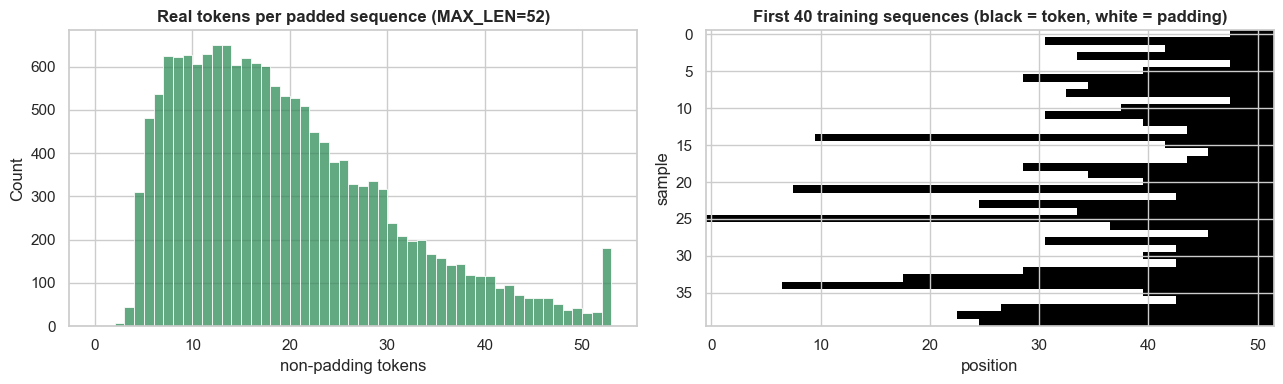

TAKEAWAY -> Sequences are padded/truncated to 52 tokens: 0.94% of train texts are truncated and 1.70% / 3.74% of train / test tokens map to <OOV>.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
lens = (X_seq["train"] != PAD).sum(1)
sns.histplot(lens, bins=range(0, MAX_LEN + 2), ax=axes[0], color="seagreen"); axes[0].set_title(f"Real tokens per padded sequence (MAX_LEN={MAX_LEN})")
axes[0].set_xlabel("non-padding tokens")
im = axes[1].imshow((X_seq["train"][:40] != PAD), aspect="auto", cmap="Greys"); axes[1].set_title("First 40 training sequences (black = token, white = padding)")
axes[1].set_xlabel("position"); axes[1].set_ylabel("sample")
plt.tight_layout(); save_fig(fig, "19_sequence_padding"); plt.show()
note("19_sequence_padding", f"Sequences are padded/truncated to {MAX_LEN} tokens: {trunc_rate['train']:.2f}% of train texts are truncated and "
     f"{oov_rate['train']:.2f}% / {oov_rate['test']:.2f}% of train / test tokens map to <OOV>.")

The plots show the number of real tokens per sequence and how the padding looks. OOV is the percentage of words that are not in the vocabulary.

## 6. Checks

Checking that the shapes match and that words that only appear in test are not in the vocabularies.

In [12]:
for s in SPLITS:
    assert X_tfidf[s].shape[0] == X_seq[s].shape[0] == len(y[s]) == len(data[s]) == len(scaled[s])
only_test = set(w for t in test.text_ml for w in t.split()) - set(w for t in train.text_ml for w in t.split())
assert not (only_test & set(tfidf.get_feature_names_out())), "test-only vocabulary leaked into TF-IDF"
assert not (only_test & set(vocab)), "test-only vocabulary leaked into the sequence vocabulary"
assert all(X_seq[s].min() >= 0 and X_seq[s].max() < MAX_WORDS for s in SPLITS)
assert all(set(np.unique(y[s])) == set(range(6)) for s in SPLITS)
assert not any(data[s].isna().any().any() for s in SPLITS)
print(f"All sanity checks passed ✔   ({len(only_test)} words occur only in test and were correctly NOT added to any vocabulary)")

All sanity checks passed ✔   (981 words occur only in test and were correctly NOT added to any vocabulary)


## 7. Save

The processed data is saved in `data/processed/`.

In [13]:
keep = ["text", "text_ml", "label", "label_id", "is_length_outlier"] + NUM + [f"{c}_scaled" for c in NUM]
for s, d in data.items():
    d[keep].to_csv(PROC / f"{s}_processed.csv", index=False)
    sp.save_npz(PROC / f"tfidf_{s}.npz", X_tfidf[s])
    np.save(PROC / f"seq_{s}.npy", X_seq[s]); np.save(PROC / f"y_{s}.npy", y[s])
joblib.dump(tfidf, PROC / "tfidf_vectorizer.joblib")
json.dump({"vocab": vocab, "pad_id": PAD, "oov_id": OOV, "max_words": MAX_WORDS, "max_len": MAX_LEN, "padding": "pre", "truncating": "pre"},
          open(PROC / "vocab.json", "w"))

summary = {"rows": {s: len(d) for s, d in data.items()}, "tfidf_shape": list(X_tfidf["train"].shape), "max_len": MAX_LEN, "max_words": MAX_WORDS,
           "vocab_size": len(vocab) + 2, "oov_rate_pct": oov_rate, "truncated_pct": trunc_rate, "log1p_features": SKEWED, "class_weights": class_weights}
(REP / "preprocessing_summary.json").write_text(json.dumps(summary, indent=2))
with open(REP / "figure_notes_preprocessing.md", "w", encoding="utf-8") as f:
    f.write("# Figure notes — preprocessing\n\n")
    for k, v in NOTES.items():
        f.write(f"- **images/{k}.png** — {v}\n")
pd.DataFrame({"file": sorted(p.name for p in PROC.iterdir()),
              "size_MB": [round(p.stat().st_size / 1e6, 2) for p in sorted(PROC.iterdir())]})

,file,size_MB
0,label_mapping.json,0.00
1,numeric_scaler.joblib,0.00
2,seq_test.npy,0.42
3,seq_train.npy,3.31
4,seq_val.npy,0.41
5,test_clean.csv,0.22
6,test_processed.csv,0.63
7,tfidf_test.npz,0.16
8,tfidf_train.npz,1.33
9,tfidf_val.npz,0.16
